In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, binom

In [2]:
# Parameters
alpha = 0.95
beta = 0.05
lam = 0.97
theta = 0.97
M = 1010

# Download S&P 500 data
ticker = "^GSPC"

data = yf.download(
    ticker,
    start="2016-05-23",
    end="2026-05-23",
    auto_adjust=True,
    progress=False
)

# Extract closing prices
prices = data["Close"]

if isinstance(prices, pd.DataFrame):
    prices = prices.iloc[:, 0]

prices = prices.dropna()
prices.name = "Close"

# Number of observations
N = len(prices)

print("First 5 observations:")
display(prices.head())

print("Last 5 observations:")
display(prices.tail())

print(f"Total number of price observations N = {N}")

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/yfinance/scrapers/history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()


First 5 observations:


Date
2016-05-23    2048.040039
2016-05-24    2076.060059
2016-05-25    2090.540039
2016-05-26    2090.100098
2016-05-27    2099.060059
Name: Close, dtype: float64

Last 5 observations:


Date
2026-05-18    7403.049805
2026-05-19    7353.609863
2026-05-20    7432.970215
2026-05-21    7445.720215
2026-05-22    7473.470215
Name: Close, dtype: float64

Total number of price observations N = 2515


In [3]:
#Historical VaR and exceedances

# Daily log returns
returns = np.log(prices / prices.shift(1)).dropna()

# Full loss operator
losses = 1 - np.exp(returns)

# Number of returns and evaluation periods
N_returns = len(returns)
J = N_returns - M

print(f"Number of log returns: {N_returns}")
print(f"Number of evaluation periods: {J}")

# Historical VaR using rolling window
historical_var = []
historical_exceed = []
evaluation_dates = []

for i in range(M, N_returns):

    # Previous 1010 losses, excluding the current day
    window = losses.iloc[i-M:i]

    # Historical 95% VaR
    var_t = np.quantile(window, alpha)

    # Actual loss on current day
    actual_loss = losses.iloc[i]

    # Exceedance indicator
    exceed = int(actual_loss > var_t)

    historical_var.append(var_t)
    historical_exceed.append(exceed)
    evaluation_dates.append(losses.index[i])

# Store results
results = pd.DataFrame({
    "Actual_Loss": losses.iloc[M:].values,
    "Historical_VaR": historical_var,
    "Historical_Exceed": historical_exceed
}, index=evaluation_dates)

print("Historical simulation results:")
display(results.head())

print(
    "Number of historical exceedances:",
    results["Historical_Exceed"].sum()
)

print(
    "Historical exceedance rate:",
    results["Historical_Exceed"].mean()
)

Number of log returns: 2514
Number of evaluation periods: 1504
Historical simulation results:


,Actual_Loss,Historical_VaR,Historical_Exceed
2020-05-29,-0.004812,0.017304,0
2020-06-01,-0.003751,0.017304,0
2020-06-02,-0.008211,0.017304,0
2020-06-03,-0.013649,0.017304,0
2020-06-04,0.003369,0.017304,0


Number of historical exceedances: 55
Historical exceedance rate: 0.036569148936170214


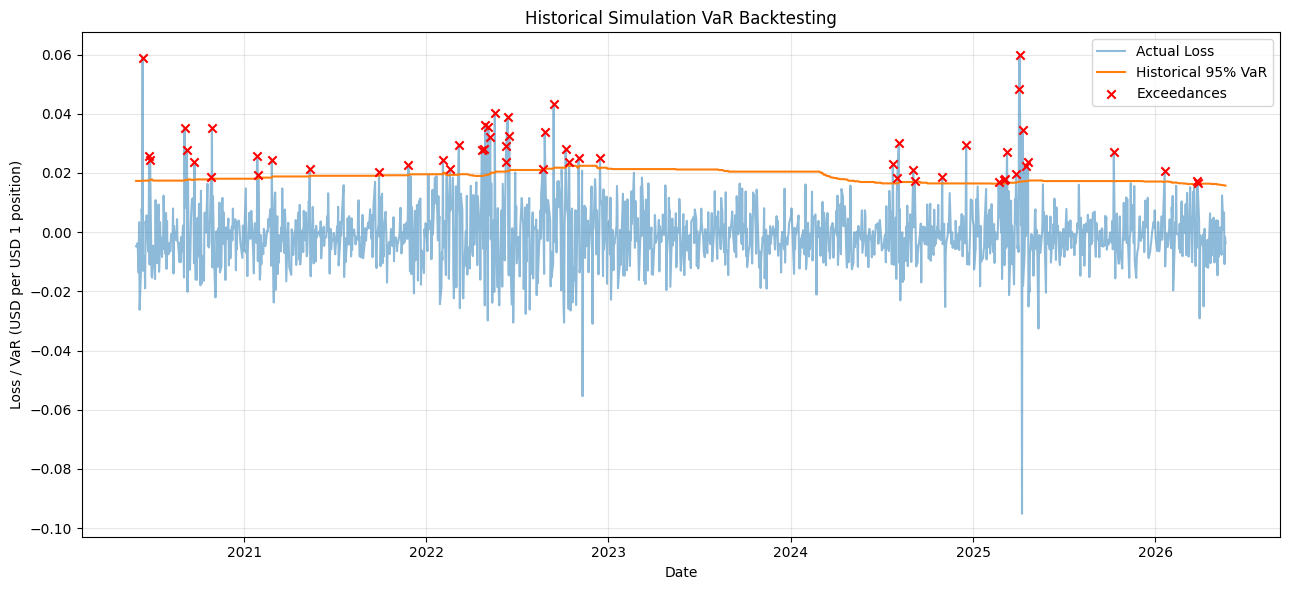

In [4]:
#Plot VaR and exceedances
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    results.index,
    results["Actual_Loss"],
    label="Actual Loss",
    alpha=0.5
)

ax.plot(
    results.index,
    results["Historical_VaR"],
    label="Historical 95% VaR",
    linewidth=1.5
)

exceedances = results[
    results["Historical_Exceed"] == 1
]

ax.scatter(
    exceedances.index,
    exceedances["Actual_Loss"],
    color="red",
    marker="x",
    label="Exceedances",
    zorder=3
)

ax.set_title("Historical Simulation VaR Backtesting")
ax.set_xlabel("Date")
ax.set_ylabel("Loss / VaR (USD per USD 1 position)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
#EWMA VaR and exceedances

# Initialize using the first 1010 log returns
initial_returns = returns.iloc[:M]

mu = initial_returns.mean()
variance = initial_returns.var(ddof=1)

ewma_var = []
ewma_exceed = []

for i in range(M, N_returns):

    # Forecast using information up to previous day
    sigma = np.sqrt(variance)

    var_t = 1 - np.exp(
        mu + sigma * norm.ppf(1 - alpha)
    )

    # Today's observed loss
    actual_loss = losses.iloc[i]

    exceed = int(actual_loss > var_t)

    ewma_var.append(var_t)
    ewma_exceed.append(exceed)

    # Update parameters after observing today's return
    x_t = returns.iloc[i]

    new_variance = (
        theta * variance
        + (1 - theta) * (x_t - mu)**2
    )

    new_mu = (
        lam * mu
        + (1 - lam) * x_t
    )

    variance = new_variance
    mu = new_mu

# Add to results
results["EWMA_VaR"] = ewma_var
results["EWMA_Exceed"] = ewma_exceed

display(results.head())

print(
    "EWMA exceedances:",
    results["EWMA_Exceed"].sum()
)

print(
    "EWMA exceedance rate:",
    results["EWMA_Exceed"].mean()
)

,Actual_Loss,Historical_VaR,Historical_Exceed,EWMA_VaR,EWMA_Exceed
2020-05-29,-0.004812,0.017304,0,0.019830,0
2020-06-01,-0.003751,0.017304,0,0.019436,0
2020-06-02,-0.008211,0.017304,0,0.019064,0
2020-06-03,-0.013649,0.017304,0,0.018662,0
2020-06-04,0.003369,0.017304,0,0.018325,0


EWMA exceedances: 94
EWMA exceedance rate: 0.0625


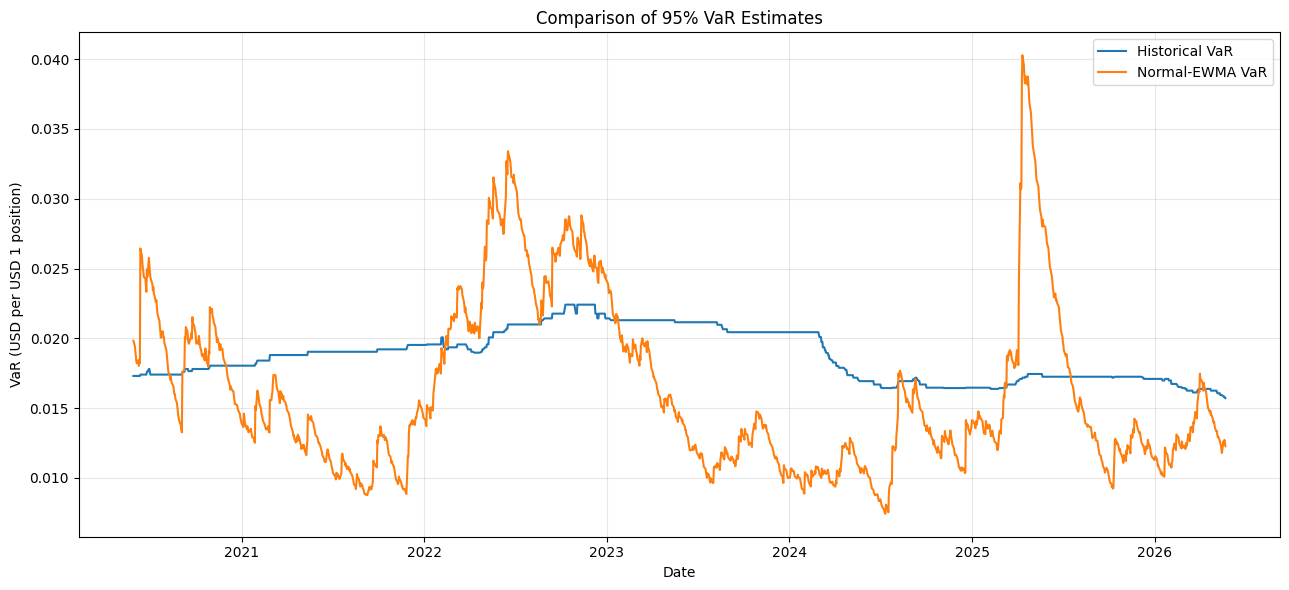

In [6]:
#Compare both VaR models

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    results.index,
    results["Historical_VaR"],
    label="Historical VaR"
)

ax.plot(
    results.index,
    results["EWMA_VaR"],
    label="Normal-EWMA VaR"
)

ax.set_title("Comparison of 95% VaR Estimates")
ax.set_xlabel("Date")
ax.set_ylabel("VaR (USD per USD 1 position)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
#Confidence interval

# Theoretical exceedance probability
p = 1 - alpha

# Number of backtesting periods
J = len(results)

# Binomial 95% confidence interval
lower = int(binom.ppf(beta / 2, J, p))
upper = int(binom.ppf(1 - beta / 2, J, p))

# Observed exceedance counts
historical_count = int(
    results["Historical_Exceed"].sum()
)

ewma_count = int(
    results["EWMA_Exceed"].sum()
)

# Backtesting decisions
historical_pass = lower <= historical_count <= upper
ewma_pass = lower <= ewma_count <= upper

summary = pd.DataFrame({
    "Method": ["Historical Simulation", "Normal-EWMA"],
    "Exceedances": [historical_count, ewma_count],
    "Exceedance Rate": [
        historical_count / J,
        ewma_count / J
    ],
    "Expected Rate": [p, p],
    "Inside 95% Interval": [
        historical_pass,
        ewma_pass
    ]
})

print(f"Evaluation periods: {J}")
print(f"Expected exceedances: {J*p:.2f}")
print(f"95% interval: [{lower}, {upper}]")

display(summary)

Evaluation periods: 1504
Expected exceedances: 75.20
95% interval: [59, 92]


,Method,Exceedances,Exceedance Rate,Expected Rate,Inside 95% Interval
0,Historical Simulation,55,0.036569,0.05,False
1,Normal-EWMA,94,0.062500,0.05,False


### Task 4: VaR Backtesting Results and Interpretation

I evaluate the performance of the Historical Simulation and Normal-EWMA VaR models over 1,504 trading days.

For a 95% VaR model, the theoretical probability of an exceedance is 5%. Therefore, the expected number of exceedances is:

\[
E[K]=1504\times0.05=75.2
\]

Assuming independent exceedances, the number of exceedances follows a binomial distribution:

\[
K\sim Binomial(1504,0.05)
\]

Using the 2.5th and 97.5th percentiles of this distribution, we obtain the 95% interval:

\[
[59,92]
\]

**Historical Simulation:**

The model produces 55 exceedances, corresponding to an exceedance rate of 3.66%. Since 55 is below the lower bound of 59, the model fails the backtest at the 5% significance level.

This result suggests that the Historical Simulation method is relatively conservative, producing VaR estimates that are too high relative to the observed frequency of losses.

**Normal-EWMA:**

The model produces 94 exceedances, corresponding to an exceedance rate of 6.25%. Since 94 exceeds the upper bound of 92, the model also fails the backtest at the 5% significance level.

This result suggests that the Normal-EWMA model underestimates portfolio tail risk. One possible explanation is that financial returns exhibit heavier tails than those predicted by the normal distribution.

**Conclusion:**

Neither model passes the exceedance-count backtest at the 95% confidence level.

Historical Simulation appears overly conservative, while Normal-EWMA appears to underestimate risk.

Although both models fail this test, the observed exceedance rates are relatively close to the theoretical 5% level. Further analysis of the independence and clustering of exceedances would help provide a more complete evaluation of their performance.